In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
(xtrain,ytrain),(xtest,ytest)=(keras.datasets.fashion_mnist.load_data())

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 10s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 12s 3us/step


In [3]:
classes = ["T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"]

In [4]:
xtrain = xtrain.astype("float32")/127.5-1.0
xtest = xtest.astype("float32")/127.5-1.0

In [5]:
xtest = xtrain[-6000:]
ytest = ytrain[-6000:]
xtrain = xtrain[:-6000]
ytrain = ytrain[:-6000]

In [8]:
model = keras.Sequential([
    layers.Input(shape=(28,28)),
    layers.Flatten(),
    layers.Dense(512,activation="relu"),
    layers.Dense(256,activation="relu"),
    layers.Dense(128,activation="relu"),
    layers.Dense(64,activation="relu"),
    layers.Dense(10)
])

In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │         401,920 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 575,050 (2.19 MB)

 Trainable params: 575,050 (2.19 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.compile( optimizer=keras.optimizers.Adam(learning_rate=0.001), loss=keras.losses.SparseCategoricalCrossentropy( from_logits=True ), metrics=["accuracy"] )

In [12]:
history=model.fit(
    xtrain,
    ytrain,
    epochs=15,
    batch_size=64,
    validation_data=(xtest,ytest),
    shuffle=True,
    verbose=1
)

Epoch 1/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 18ms/step - accuracy: 0.8185 - loss: 0.4966 - val_accuracy: 0.8458 - val_loss: 0.4287
Epoch 2/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 18ms/step - accuracy: 0.8617 - loss: 0.3783 - val_accuracy: 0.8348 - val_loss: 0.4625
Epoch 3/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 21s 18ms/step - accuracy: 0.8750 - loss: 0.3382 - val_accuracy: 0.8555 - val_loss: 0.4118
Epoch 4/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 21s 18ms/step - accuracy: 0.8842 - loss: 0.3133 - val_accuracy: 0.8688 - val_loss: 0.3589
Epoch 5/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 18ms/step - accuracy: 0.8925 - loss: 0.2909 - val_accuracy: 0.8768 - val_loss: 0.3456
Epoch 6/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 21s 18ms/step - accuracy: 0.8967 - loss: 0.2775 - val_accuracy: 0.8827 - val_loss: 0.3485
Epoch 7/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 18ms/step - accuracy: 0.9011 - loss: 0.2638 - val_accuracy: 0.8807 - val_loss: 0.3472
Epoch 8/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9071 - loss: 0.2480 - 

In [13]:
test_loss,test_accuracy = model.evaluate(
    xtest,
    ytest,
    verbose=0
)
print("Model Evaluation")
print(f"Test Loss:{test_loss:.4f}")
print(f"Test Accuracy:{test_accuracy*100:.2f}%")

Model Evaluation
Test Loss:0.3661
Test Accuracy:89.15%


In [14]:
history_df = pd.DataFrame(history.history)
history_df.index = np.arange(1,len(history_df)+1)
history_df.index.name = "Epoch"

In [15]:
print("Training History:")
print(history_df.round(4))

Training History:
       accuracy    loss  val_accuracy  val_loss
Epoch                                          
1        0.8185  0.4966        0.8458    0.4287
2        0.8617  0.3783        0.8348    0.4625
3        0.8750  0.3382        0.8555    0.4118
4        0.8842  0.3133        0.8688    0.3589
5        0.8925  0.2909        0.8768    0.3456
6        0.8967  0.2775        0.8827    0.3485
7        0.9011  0.2638        0.8807    0.3472
8        0.9071  0.2480        0.8840    0.3386
9        0.9104  0.2384        0.8818    0.3364
10       0.9140  0.2253        0.8833    0.3423
11       0.9192  0.2172        0.8867    0.3315
12       0.9223  0.2046        0.8853    0.3372
13       0.9263  0.1973        0.8883    0.3486
14       0.9293  0.1868        0.8915    0.3360
15       0.9307  0.1817        0.8915    0.3661


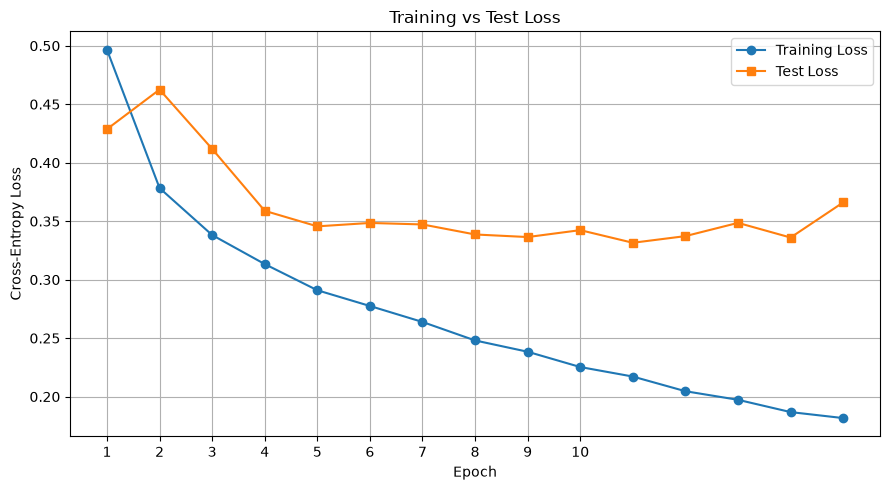

In [20]:
plt.figure(figsize=(9, 5))
plt.plot( history.history["loss"],
          label="Training Loss",
          marker="o" )
plt.plot( history.history["val_loss"],
          label="Test Loss", marker="s" )
plt.title("Training vs Test Loss")
plt.xlabel("Epoch") 
plt.ylabel("Cross-Entropy Loss") 
plt.legend() 
plt.grid(True) 
plt.xticks(range(10), range(1, 11)) 
plt.tight_layout() 
plt.show()

In [22]:
logits = model.predict(xtest[:10], verbose=0)
predicted_labels = np.argmax(logits, axis=1)
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(xtest[i].squeeze(), cmap="gray", vmin=0, vmax=1)

    # Predicted and actual class names
    predicted_name = classes[predicted_labels[i]]
    actual_label = int(np.asarray(ytest[i]).squeeze())
    actual_name = classes[actual_label]

    # Green = correct, Red = incorrect
    color = "green" if predicted_labels[i] == actual_label else "red"

    plt.title(
        f"Pred: {predicted_name}\nActual: {actual_name}",
        color=color,
        fontsize=9
    )

    plt.axis("off")

plt.suptitle("FashionMNIST Predictions", fontsize=14)
plt.tight_layout()
plt.show()

SyntaxError: expected ':' (716596582.py, line 10)